Đang tải dữ liệu...
Số lượt đánh giá sau lọc: 92729
Số người dùng sau lọc: 364
Số phim sau lọc: 9625

--- PHÂN CHIA DỮ LIỆU (TRAIN/TEST SPLIT) ---
Số lượng đánh giá tập Train: 74183
Số lượng đánh giá tập Test: 18546

Đang chạy Truncated SVD độc quyền trên tập Train...
Đã lưu biểu đồ phương sai tại 'svd_variance.png'
Đang chạy K-Means trên các vector tiềm ẩn (Latent Vectors)...
Huấn luyện hoàn tất!

--- CHẠY THỬ NGHIỆM VỚI PHIM HARRY POTTER (Tạo file CSV minh chứng) ---
Đã tìm thấy phim gốc: Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001) (Cụm K-Means: 6)
Đã xuất danh sách gợi ý ra tệp: recommendations_Harry_Potter_and_the_Sorcerer's_Stone_(a.k.a._Harry_Potter_and_the_Philosopher's_Stone)_(2001).csv

--- KHỞI TẠO GIAO DIỆN DEMO ---


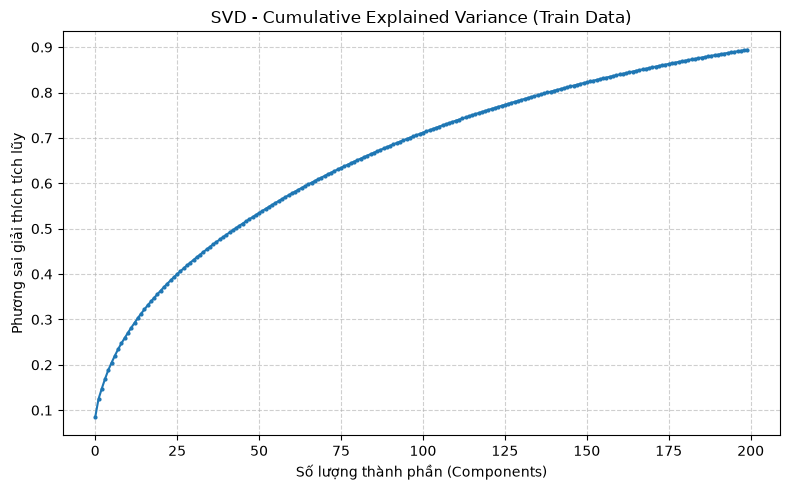

In [ ]:
import os
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import warnings
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.model_selection import train_test_split # Import thư viện chia tập

warnings.filterwarnings('ignore')

# --- 1. CẤU HÌNH THAM SỐ (Khớp với báo cáo) ---
RANDOM_SEED = 42
MIN_RATINGS = 55
N_SVD_COMPONENTS = 200
N_CLUSTERS = 10
N_INIT = 10

# --- 2. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---
data_dir = "ml-latest-small"
ratings_path = os.path.join(data_dir, 'ratings.csv')
movies_path = os.path.join(data_dir, 'movies.csv')
tags_path = os.path.join(data_dir, 'tags.csv') # Đã bổ sung tags.csv

print("Đang tải dữ liệu...")
ratings = pd.read_csv(ratings_path)
movies = pd.read_csv(movies_path)

# Xử lý tags và gộp vào metadata như báo cáo đã nêu
if os.path.exists(tags_path):
    tags = pd.read_csv(tags_path)
    tags_grouped = tags.groupby('movieId')['tag'].apply(lambda x: '|'.join(x.astype(str))).reset_index()
    movies = pd.merge(movies, tags_grouped, on='movieId', how='left')
    movies['tag'] = movies['tag'].fillna('')
    movies['metadata'] = movies['genres'] + '|' + movies['tag']
else:
    print("Cảnh báo: Không tìm thấy file tags.csv, chỉ sử dụng genres làm metadata.")
    movies['metadata'] = movies['genres']

# Lọc user có >= 55 đánh giá
user_counts = ratings['userId'].value_counts()
valid_users = user_counts[user_counts >= MIN_RATINGS].index
ratings_filtered = ratings[ratings['userId'].isin(valid_users)].copy()

valid_movies = ratings_filtered['movieId'].unique()
movies_filtered = movies[movies['movieId'].isin(valid_movies)].copy()

print(f"Số lượt đánh giá sau lọc: {len(ratings_filtered)}")
print(f"Số người dùng sau lọc: {ratings_filtered['userId'].nunique()}")
print(f"Số phim sau lọc: {ratings_filtered['movieId'].nunique()}")

# --- 3. CHIA DỮ LIỆU, XÂY DỰNG MA TRẬN VÀ HUẤN LUYỆN SVD, K-MEANS ---
print("\n--- PHÂN CHIA DỮ LIỆU (TRAIN/TEST SPLIT) ---")
# Chia dữ liệu thành tập Train (80%) và Test (20%)
train_data, test_data = train_test_split(ratings_filtered, test_size=0.2, random_state=RANDOM_SEED)
print(f"Số lượng đánh giá tập Train: {len(train_data)}")
print(f"Số lượng đánh giá tập Test: {len(test_data)}")

# Tạo từ điển ánh xạ (mapping) ID
user_ids = ratings_filtered['userId'].unique()
movie_ids = ratings_filtered['movieId'].unique()
user_to_idx = {uid: i for i, uid in enumerate(user_ids)}
movie_to_idx = {mid: i for i, mid in enumerate(movie_ids)}
idx_to_movie = {i: mid for mid, i in movie_to_idx.items()}

# CHỈ XÂY DỰNG MA TRẬN THƯA TRÊN TẬP TRAIN (Chống data leakage)
row_ind_train = train_data['userId'].map(user_to_idx).values
col_ind_train = train_data['movieId'].map(movie_to_idx).values
data_train = train_data['rating'].values

R_train = csr_matrix((data_train, (row_ind_train, col_ind_train)), shape=(len(user_ids), len(movie_ids)))

print("\nĐang chạy Truncated SVD độc quyền trên tập Train...")
svd = TruncatedSVD(n_components=N_SVD_COMPONENTS, random_state=RANDOM_SEED)
svd.fit(R_train) # Chỉ fit trên R_train
movie_factors = svd.components_.T

# Vẽ biểu đồ phương sai và LƯU ra file ảnh
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', markersize=2)
plt.xlabel('Số lượng thành phần (Components)')
plt.ylabel('Phương sai giải thích tích lũy')
plt.title('SVD - Cumulative Explained Variance (Train Data)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('svd_variance.png') 
print("Đã lưu biểu đồ phương sai tại 'svd_variance.png'")

print("Đang chạy K-Means trên các vector tiềm ẩn (Latent Vectors)...")
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=N_INIT)
movie_clusters = kmeans.fit_predict(movie_factors)
print("Huấn luyện hoàn tất!")

# --- 4. HÀM GỢI Ý PHIM ---
def recommend_similar_movies(target_movie_title, top_k=10, save_csv=False):
    target_movie_title = target_movie_title.strip()
    movie_row = movies_filtered[movies_filtered['title'].str.contains(target_movie_title, case=False, na=False, regex=False)]
    
    if movie_row.empty:
        return f"Không tìm thấy phim nào chứa từ khóa: '{target_movie_title}'."
    
    target_movie = movie_row.iloc[0]
    target_id = target_movie['movieId']
    target_title_full = target_movie['title']
    
    if target_id not in movie_to_idx:
        return f"Phim '{target_title_full}' không có trong tập huấn luyện."
        
    target_idx = movie_to_idx[target_id]
    target_cluster = movie_clusters[target_idx]
    cluster_indices = np.where(movie_clusters == target_cluster)[0]
    
    target_vector_norm = normalize(movie_factors[target_idx].reshape(1, -1))
    cluster_vectors_norm = normalize(movie_factors[cluster_indices])
    similarities = cosine_similarity(target_vector_norm, cluster_vectors_norm).flatten()
    
    sorted_idx = np.argsort(similarities)[::-1]
    
    recs = []
    for i in sorted_idx:
        if len(recs) >= top_k: break
        candidate_idx = cluster_indices[i]
        if candidate_idx == target_idx: continue
        
        cand_movie_id = idx_to_movie[candidate_idx]
        cand_movie_info = movies_filtered[movies_filtered['movieId'] == cand_movie_id].iloc[0]
        
        sim_score = similarities[i]
        metadata_display = cand_movie_info.get('metadata', '')
        
        recs.append({
            'Movie ID': cand_movie_id,
            'Tên phim': cand_movie_info['title'],
            'Thể loại & Tags': metadata_display[:65] + '...' if len(metadata_display) > 65 else metadata_display,
            'Cosine Similarity': round(sim_score, 4)
        })
        
    print(f"Đã tìm thấy phim gốc: {target_title_full} (Cụm K-Means: {target_cluster})")
    df_recs = pd.DataFrame(recs)
    
    # Hỗ trợ xuất file CSV để nộp minh chứng minh họa
    if save_csv and not df_recs.empty:
        safe_title = target_title_full.replace(' ', '_').replace(':', '').replace('/', '')
        filename = f"recommendations_{safe_title}.csv"
        df_recs.to_csv(filename, index=False, encoding='utf-8-sig')
        print(f"Đã xuất danh sách gợi ý ra tệp: {filename}")
        
    return df_recs

# --- 5. CHẠY THỬ NGHIỆM ĐỂ XUẤT FILE MINH CHỨNG CHO BÁO CÁO ---
print("\n--- CHẠY THỬ NGHIỆM VỚI PHIM HARRY POTTER (Tạo file CSV minh chứng) ---")
recommend_similar_movies("Harry Potter", top_k=10, save_csv=True)

# --- 6. GIAO DIỆN NOTEBOOK (Dành cho phần Demo Thuyết trình) ---
print("\n--- KHỞI TẠO GIAO DIỆN DEMO ---")
movie_input = widgets.Text(
    value='Harry Potter', # Đặt sẵn ví dụ "ăn tiền" nhất
    placeholder='Nhập tên phim (VD: Matrix, Godfather, Harry Potter)',
    description='Tên phim:',
    layout=widgets.Layout(width='50%')
)

button = widgets.Button(
    description='Gợi ý phim tương tự',
    button_style='success'
)

output = widgets.Output()

def khi_nhan_nut(b):
    with output:
        clear_output(wait=True)
        print(f"Đang tìm kiếm phim tương tự với: '{movie_input.value}'...\n")
        try:
            # Khi chạy demo bằng nút bấm thì không cần lưu CSV nữa
            ket_qua = recommend_similar_movies(movie_input.value, top_k=10, save_csv=False)
            if isinstance(ket_qua, str):
                print(ket_qua)
            else:
                display(ket_qua)
        except Exception as e:
            print("Đã xảy ra lỗi:", e)

button.on_click(khi_nhan_nut)

display(widgets.VBox([
    widgets.HTML("<h3>Hệ thống gợi ý phim - SVD & K-Means</h3>"),
    widgets.HBox([movie_input, button]),
    output
]))